# Binarizarea imaginilor: metoda Otsu

Laboratorul 5, DEPI

# 1. Obiectiv

Citirea și afișarea imaginilor în tonuri de gri în Matlab, interpretarea
histogramelor, și implementarea binarizării imaginilor prin metoda Otsu
pe baza varianțelor grupurilor.

# 2. Aspecte teoretice

## 2.1 O imagine în tonuri de gri este o matrice

O imagine digitală este o matrice de pixeli. O imagine în tonuri de gri
stochează câte o valoare a intensității pentru fiecare pixel, într-o
matrice `I`:

- `I(r,c)` este pixelul de pe linia `r`, coloana `c`.
- Valori mici corespund pixelilor întunecați, iar cele mari pixelilor
  luminoși.
- Pentru o imagine pe 8 biți, stocată ca `uint8`, pixelii sunt numere
  întregi de la 0 (negru) la 255 (alb).
- Dacă imaginea este stocată ca `double`, pixelii sunt numere reale, fie
  în intervalul 0–255, fie în intervalul 0–1.

În acest laborator, preferăm valori ale pixelilor în intervalul 0–1, de
tip `double`, pentru a putea efectua calcule precise.

De exemplu, aceasta este o imagine mică în tonuri de gri:

``` matlab
I_small = [0 0.25 0.5 1; 0 0.25 0.5 1; 0 0.25 0.5 1];
figure
imshow(I_small)
```

În exemplul de mai jos:

- `imread()` citește o imagine dintr-un fișier;
- `im2double()` convertește o imagine cu valori întregi la tipul
  `double` și îi rescalează intensitățile în intervalul 0–1;
- `size(I)` întoarce numărul de linii și de coloane (ca pentru orice
  matrice Matlab);
- `imshow()` afișează imaginea.

``` matlab
Iraw = imread('coins.png');
I = im2double(Iraw);
size(I)
figure
imshow(I)
```

Imaginile folosite în acest laborator sunt deja în tonuri de gri, deci
nu este necesară conversia culorilor. O imagine color RGB ar avea trei
canale, și poate fi convertită în tonuri de gri cu `rgb2gray()`.

Pentru imaginile pe 8 biți din acest laborator, `im2double(Iraw)` este
echivalent cu `double(Iraw)/255`. Valoarea 0 reprezintă negrul, iar 1
reprezintă albul. Conversia folosește întreaga scară de intensități pe 8
biți, nu cea mai mică și cea mai mare valoare prezente efectiv în
imagine; acestea nu devin neapărat 0 și 1.

Conversia nu înseamnă doar schimbarea tipului: `double(Iraw)` păstrează
intensitățile pe 8 biți pe scara 0–255. De asemenea, `im2double()` nu
rescalează un argument care este deja `double`; convertiți direct
imaginea originală cu valori întregi.

De acum înainte, folosiți imaginea normalizată `I` atât pentru afișare,
cât și pentru calcule. `imshow(I)` folosește intervalul 0–1 pentru o
imagine `double`; nu este necesar un argument suplimentar pentru
intervalul de afișare. Consultați [documentația
`im2double`](https://www.mathworks.com/help/matlab/ref/im2double.html).

## 2.2 De la pixeli la histogramă

Histograma imaginii numără câți pixeli au fiecare intensitate și arată
distribuția intensităților.

Folosiți `imhist()` direct pe imagine pentru a afișa histograma
intensităților:

``` matlab
figure
imhist(I)
xlabel('Intensitate')
ylabel('Număr de pixeli')
```

Pentru o imagine în tonuri de gri, `imhist(I)` folosește implicit 256 de
intervale. Pentru imaginea noastră normalizată, de tip `double`,
pozițiile intervalelor acoperă domeniul 0–1. Folosiți `imhist(I,256)`
pentru a specifica explicit acest număr de intervale la compararea
imaginilor. Spre deosebire de o histogramă normalizată ca densitate de
probabilitate, acest grafic arată numărul de pixeli. Consultați
[documentația
`imhist`](https://www.mathworks.com/help/images/ref/imhist.html).

Pentru calculul pragurilor, `I(:)` reunește toți pixelii într-un singur
vector coloană, fără a le schimba tipul sau scara intensităților:

``` matlab
pixels = I(:);
```

Două zone de concentrare a intensităților pot sugera două grupuri, de
exemplu regiuni întunecate și luminoase. Histograma numără
intensitățile, dar nu descrie pozițiile pixelilor în imagine.

<figure>
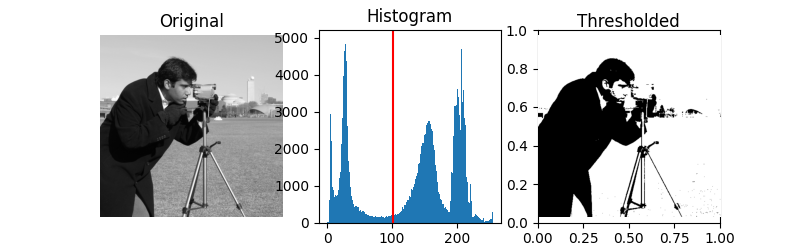
<figcaption aria-hidden="true">O fotografie reală în tonuri de gri,
histograma intensităților și binarizarea sa. Linia roșie marchează
pragul Otsu în acest exemplu publicat.</figcaption>
</figure>

Fotografie: Lav Varshney (CC0), prin [setul de date camera din
scikit-image](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.camera).
Figura comparativă: [exemplul de binarizare din
scikit-image](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_thresholding.html).
Această ilustrație externă folosește valori pe 8 biți, pe scara 0–255;
împărțiți aceste intensități și pragul la 255 pentru a le exprima pe
scara 0–1 folosită aici. Imaginea binară separă pixelii întunecați de
cei luminoși, nu neapărat întreaga persoană de fundal.

## 2.3 Observație: egalizarea histogramei

O imagine ale cărei intensități ocupă doar o porțiune îngustă din
intervalul 0–1 poate avea un contrast redus. **Egalizarea histogramei**
transformă intensitățile pe baza histogramei cumulative (fracțiunea de
pixeli cu intensitatea mai mică sau egală cu fiecare valoare, ca în
cazul FR din Laboratorul 2). Valorile frecvente sunt distribuite într-un
interval mai larg, fără schimbarea pozițiilor pixelilor. Este o metodă
de îmbunătățire a contrastului, nu de binarizare sau de eliminare a
zgomotului, și nu este o prelucrare preliminară obligatorie pentru
metoda Otsu.

``` matlab
Ieq = histeq(I,256);
```

Rezultatul are aceeași dimensiune și același tip ca `I`, cu intensități
tot în intervalul 0–1. Comparați `imshow(I)` cu `imshow(Ieq)` și
`imhist(I,256)` cu `imhist(Ieq,256)`. Histograma nu devine neapărat
perfect uniformă: pixelii cu aceeași intensitate inițială primesc în
continuare aceeași valoare de ieșire. Consultați [documentația
`histeq`](https://www.mathworks.com/help/images/ref/histeq.html).

<figure>
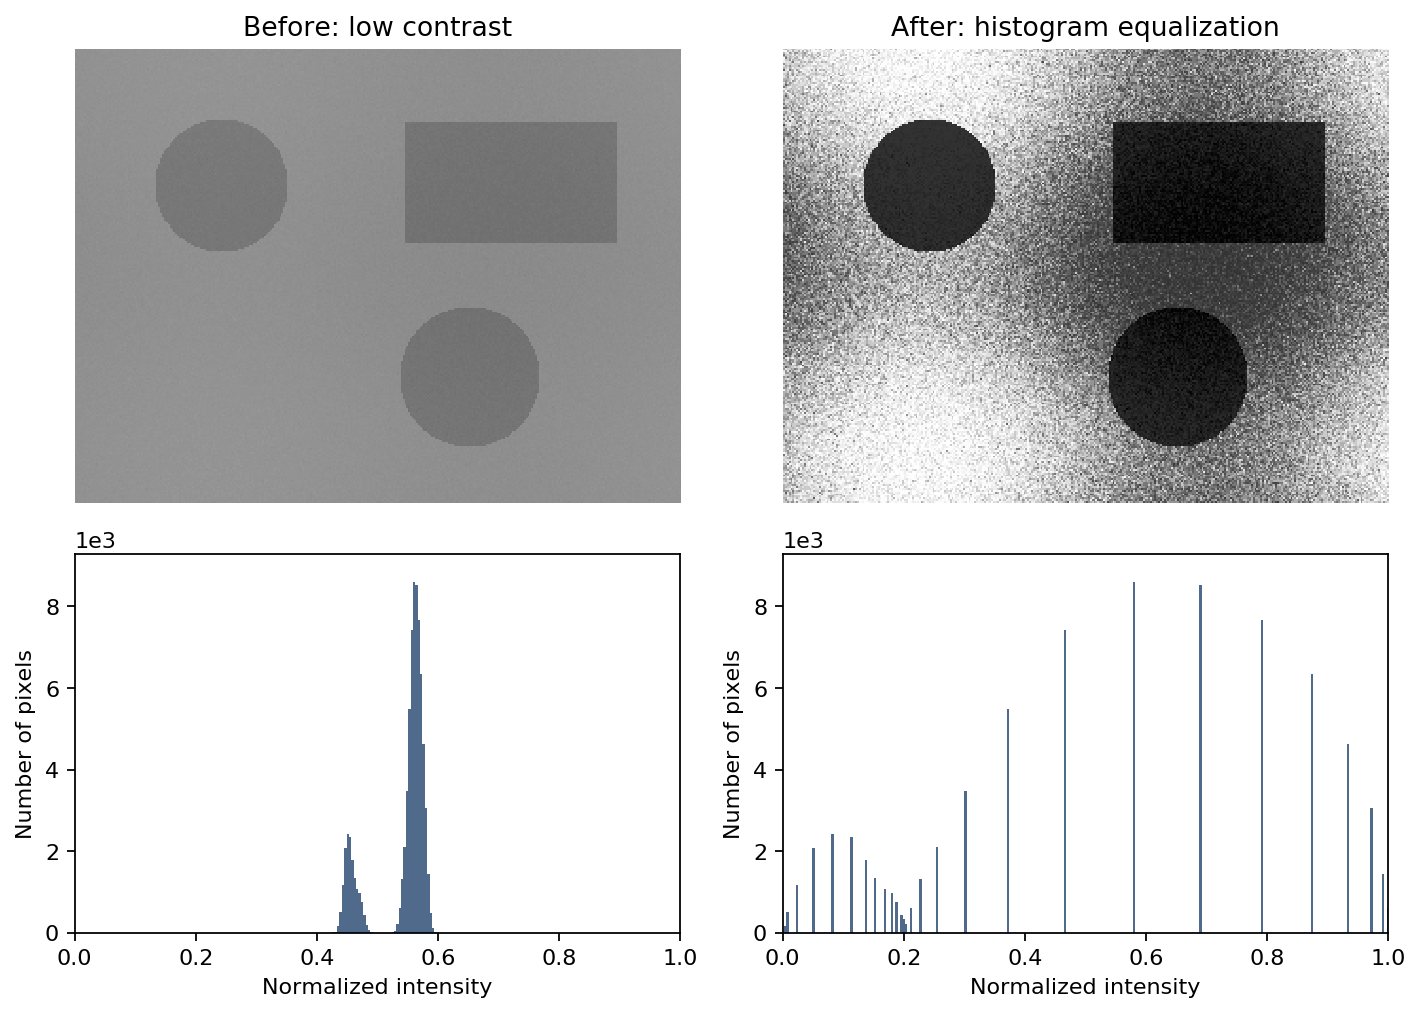
<figcaption aria-hidden="true">Egalizarea histogramei unei imagini
simulate în tonuri de gri, cu contrast redus. Ambele imagini folosesc
același interval de afișare 0–1, iar ambele histograme folosesc 256 de
intervale și aceleași scări ale axelor. Contrastul crește, dar
histograma nu este perfect uniformă, iar fluctuațiile mici ale
intensității devin mai vizibile.</figcaption>
</figure>

Pentru a compara grafice în aceeași fereastră, `subplot(2,2,1)`
selectează prima poziție dintr-o grilă de 2 pe 2. Apelați apoi
`imshow()` sau `imhist()` pentru a desena în acea poziție. Pozițiile
sunt numerotate de-a lungul primei linii, apoi de-a lungul celei de-a
doua. Folosiți același interval de afișare 0–1 pentru imagini și același
număr de intervale pentru histograme, înainte și după.

## 2.4 Compararea cu un prag și binarizarea imaginilor

**Binarizarea unei imagini** transformă o imagine în tonuri de gri
într-o imagine cu doar două valori (negru și alb). **Compararea cu un
prag** este o modalitate de binarizare: se atribuie o valoare binară
intensităților de o parte a pragului și cealaltă valoare intensităților
de cealaltă parte.

Un prag $t$ împarte intensitățile în două grupuri, cele de sub $t$ și
cele de deasupra lui $t$:

$$C_0(t)=\{x:x\le t\}, \qquad C_1(t)=\{x:x>t\}.$$

Aici, fiecare $x$ este intensitatea unui pixel. Comparația produce o
**imagine binară**:

``` matlab
BW = I > 0.5;
figure
imshow(BW)
```

`BW` are același număr de linii și de coloane ca `I`. Valorile sale sunt
`false` (afișat ca negru) și `true` (afișat ca alb). În această
convenție, pixelii albi sunt cei **deasupra** pragului. Aceasta nu
înseamnă automat că pixelii albi reprezintă obiectele de interes.

Exemple tipice de binarizare:

- **Text tipărit întunecat pe hârtie albă:** separarea cernelii de
  hârtie.
- **Notițe scrise de mână pe hârtie:** distingerea cernelii întunecate
  de hârtie, chiar și când fotografierea introduce umbre și iluminare
  neuniformă.
- **Monede luminoase pe un fundal mai întunecat:** separarea monedelor
  de fundal.

<figure>
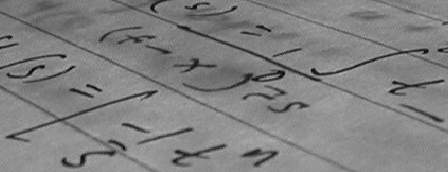
<figcaption aria-hidden="true">O fotografie reală în tonuri de gri a
unor formule matematice scrise de mână pe hârtie. Binarizarea urmărește
separarea cernelii întunecate de hârtie; umbrele pot reduce eficiența
unui singur prag global.</figcaption>
</figure>

Sursă: [imaginea cu text din
scikit-image](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.text),
provenită inițial de pe Wikipedia și aflată în domeniul public. Imaginea
în tonuri de gri, nemodificată, este disponibilă local ca
`img/Lab5_handwrittenText.png`.

Pentru text sau alte obiecte întunecate, `I > t` păstrează fundalul alb
și obiectele negre. Dacă masca dorită trebuie să marcheze obiectele ca
`true`, folosiți `I <= t`. Alegerea pragului și alegerea grupului care
reprezintă obiectele de interes sunt două decizii separate.

Problema este alegerea unui prag care să separe bine obiectele de
interes de fundal. Metoda Otsu oferă o modalitate de a face acest lucru.

## 2.5 Criteriul Otsu: grupuri compacte de intensități

Dorim ca pixelii din fiecare grup să aibă intensități similare. Metoda
Otsu alege un prag care minimizează **varianța ponderată din interiorul
grupurilor**.

Fie $N$ numărul total de pixeli, iar $N_0(t)$ și $N_1(t)$ numerele de
pixeli din cele două grupuri. Ponderile lor sunt

$$w_0(t)=\frac{N_0(t)}{N}, \qquad w_1(t)=\frac{N_1(t)}{N}.$$

Pentru un grup nevid $C_j(t)$, media și varianța se calculează astfel:

$$m_j(t)=\frac{1}{N_j(t)}\sum_{x\in C_j(t)}x,$$

$$v_j(t)=\frac{1}{N_j(t)}\sum_{x\in C_j(t)}(x-m_j(t))^2.$$

În Matlab, după extragerea intensităților unui grup nevid într-un vector
`cluster`, folosiți `mean()` și `var()` pentru a calcula $m_j(t)$ și
$v_j(t)$:

``` matlab
mj = mean(cluster);
vj = var(cluster,1);
```

Acestea sunt statistici ale **intensităților pixelilor**, nu ale
coordonatelor pixelilor sau ale măștii binare. Repetați calculele pentru
fiecare dintre cele două grupuri.

Scorul care trebuie minimizat este

$$J(t)=w_0(t)v_0(t)+w_1(t)v_1(t).$$

Ponderile contează: un grup cu puțini pixeli nu trebuie să contribuie la
fel de mult ca unul care conține majoritatea pixelilor. Nu minimizați
suma neponderată a celor două varianțe.

**Normalizarea varianței:** aici descriem toți pixelii observați în
fiecare grup, deci folosim `var(cluster,1)`, cu numitorul egal cu
numărul de pixeli din grup, nu normalizarea implicită a varianței
eșantionului din Matlab. Un grup cu un singur pixel are varianța 0.

### Căutarea tuturor pragurilor

Pentru o imagine obținută prin normalizarea intensităților pe 8 biți,
folosiți 256 de praguri candidate pe aceeași scară:

``` matlab
thresholds = (0:255)/255;
```

Acestea acoperă intervalul de la 0 la 1, cu pasul `1/255`. La fiecare
prag:

1.  Extrageți cei doi vectori de pixeli folosind indexarea logică.
2.  Dacă unul dintre vectori este vid, nu evaluați acel prag.
3.  Altfel, calculați ambele varianțe, ambele ponderi și scorul $J(t)$.
4.  Stocați scorul pentru a-l putea reprezenta grafic și a-i identifica
    minimul.

`isempty(x)` verifică dacă un vector este vid. Într-o buclă `for`,
`continue` sare peste restul iterației curente. Folosiți-le pentru a
evita calcularea varianței unui grup vid.

O posibilitate de stocare a scorurilor este inițializarea unui vector cu
infinit:

``` matlab
scores = Inf(1,256);
```

Păstrați `Inf` pentru pragurile nevalide, astfel încât acestea să nu
poată fi selectate ca minime. Pentru o imagine neconstantă, cel puțin un
prag produce două grupuri nevide. O imagine constantă nu permite nicio
împărțire validă. Dacă toate scorurile rămân `Inf`, semnalați că nu
există un prag valid, în loc să interpretați indicele returnat de
`min()` ca pe un prag valid.

**Indexare:** pragul este acum o intensitate în intervalul 0–1, nu un
indice de vector. Parcurgeți indicii întregi `k=1:numel(thresholds)`,
setați `t=thresholds(k)` și stocați scorul la poziția `k`. Al doilea
argument de ieșire al funcției `min()` oferă un indice:

``` matlab
[value, index] = min(v);
```

Folosiți acel indice pentru a găsi intensitatea corespunzătoare în
`thresholds`. Nu folosiți un prag fracționar ca indice al unui tablou
Matlab.

Mai multe praguri pot produce aceeași împărțire și același scor dacă
există goluri în histogramă. Folosiți primul prag care minimizează
scorul, returnat de `min()`. Aceasta este o convenție pentru egalități,
nu o limită fizică unică.

În acest laborator, implementați singuri căutarea. Nu o înlocuiți cu
`graythresh`, `otsuthresh` sau altă funcție de selectare automată a
pragului.

## 2.6 Rezumat: funcții și notații de cunoscut

| Sintaxă sau notație | Exemplu | Descriere |
|------------------------|------------------------|------------------------|
| `imread(filename)` | `Iraw = imread('coins.png')` | Citește o imagine dintr-un fișier |
| `size(I)` | `size(I)` | Dimensiunile imaginii (dimensiunile matricei) |
| `im2double(Iraw)` | `I = im2double(Iraw)` | Convertește o imagine cu valori întregi la intensități `double` normalizate în 0–1 |
| `imshow(I)` | `imshow(I)` | Afișează o imagine `double` normalizată sau o imagine logică |
| `I(r,c)`, `I(:)` | `I(10,20)`, `I(:)` | Accesează un pixel; reunește toți pixelii într-un vector coloană |
| `imhist(I)`, `imhist(I,n)` | `imhist(I,256)` | Afișează histograma imaginii; intensitățile normalizate acoperă intervalul 0–1 |
| `I > t` | `BW = I > 0.5` | Mască logică ce selectează pixelii deasupra unui prag |
| Indexare logică | `pixels(pixels <= t)` | Extrage intensitățile care îndeplinesc o condiție |
| `numel(x)` | `numel(pixels)` | Numărul de elemente |
| `mean(x)` | `mean(cluster)` | Intensitatea medie $m_j(t)$ a unui grup |
| `var(x,1)` | `var(cluster,1)` | Varianța normalizată cu numărul de elemente din grup |
| `isempty(x)`, `continue` | `isempty(cluster)` | Detectează un grup vid; sare peste o iterație a buclei |
| `Inf(m,n)` | `Inf(1,256)` | Inițializează o matrice sau un vector cu infinit |
| `min(x)` | `[value,index] = min(scores)` | Valoarea minimă și indicele primei sale apariții |
| `plot(x,y)` | `plot(thresholds,scores)` | Reprezintă scorul în funcție de pragul candidat |
| `histeq(I,n)` | `histeq(I,256)` | Egalizarea histogramei cu `n` intervale țintă |
| `subplot(m,n,k)` | `subplot(2,2,3)` | Selectează o poziție de afișare într-o grilă |

# 3. Exerciții

Scrieți comenzile într-un script sau live script. Etichetați figurile și
răspundeți la întrebările de interpretare în comentarii. Folosiți Matlab
cu Image Processing Toolbox pentru `imhist()` și `histeq()`. Imaginile
în tonuri de gri `coins.png` și `pout.tif` sunt incluse în acest
toolbox. Două imagini didactice suplimentare sunt disponibile în
directorul `img/` al laboratorului: imaginea simulată
`Lab5_document.png` și fotografia reală `Lab5_handwrittenText.png`.
Rulați scriptul din `Labs/` pentru ca aceste căi relative să
funcționeze. [Tutorialul de import al
imaginilor](https://www.mathworks.com/help/images/image-import-and-export.html)
folosește `pout.tif`, iar [exemplul Otsu din
documentație](https://www.mathworks.com/help/images/ref/graythresh.html)
folosește `coins.png`; acesta din urmă este o referință, nu un
înlocuitor pentru bucla pe care trebuie să o scrieți.

Alocare orientativă: 15 minute pentru Exercițiul 1, 10 pentru Exercițiul
2, 65 pentru Exercițiul 3, 10 pentru scurtul experiment din Exercițiul 4
și 20 pentru întrebările finale și verificare.

1.  Prima imagine în tonuri de gri:

    1.  Citiți `coins.png` în `Iraw`. Convertiți-o cu `im2double()` și
        stocați imaginea normalizată în `I`. Afișați `I` într-o figură.
    2.  Determinați dimensiunile imaginii. Câți pixeli conține?
        Comparați cea mai mică și cea mai mare intensitate observată în
        `Iraw` și `I`. Valorile din `I` sunt exact cele din `Iraw`
        împărțite la 255?
    3.  Citiți pixelul de pe linia 50, coloana 100. Creșterea indicelui
        liniei deplasează poziția în jos sau pe orizontală în imaginea
        afișată?
    4.  Reprezentați histograma intensităților direct cu `imhist(I)`. Ce
        intervale de intensități normalizate sunt cele mai frecvente?
    5.  Reuniți pixelii într-un vector coloană `pixels`, folosind
        `I(:)`. Folosiți acest vector pentru calcule și păstrați `I` ca
        matrice pentru afișare.

2.  Alegerea vizuală a unui prag:

    1.  Anticipați cum se modifică regiunile albe când pragul crește.
    2.  Creați și afișați imaginile binare pentru pragurile 0.3, 0.5 și
        0.7. Folosiți o grilă de afișare cu o linie și trei coloane,
        indicând pragul în titlul fiecărui grafic.
    3.  Alegeți unul dintre aceste praguri și explicați alegerea
        examinând atât imaginea, cât și histograma. Sunt toate monedele
        separate clar de fundal?

3.  Implementați metoda Otsu ca funcție:

    1.  Creați un fișier nou `otsuManual.m`, în același director cu
        scriptul, cu următorul antet de funcție:

        ``` matlab
        function [bestThreshold, minScore, scores, thresholds] = otsuManual(I)
        ```

        Argumentul de intrare `I` este o imagine în tonuri de gri, de
        tip `double`, cu valori în intervalul 0–1. Returnați pragul
        selectat, scorul său, vectorul scorurilor și vectorul pragurilor
        candidate. Încheiați funcția cu `end`.

    2.  În interiorul funcției, reuniți pixelii într-un vector, setați
        `thresholds = (0:255)/255` și inițializați scorurile cu `Inf`.
        Scrieți o buclă `for` care împarte pixelii în două grupuri la
        fiecare prag. Dacă un grup este vid, omiteți acel prag; altfel,
        calculați ambele varianțe cu `var(cluster,1)` și scorul lor
        ponderat $J(t)$. După buclă, folosiți primul minim pentru a
        selecta pragul optim. Nu folosiți o funcție Otsu automată.

    3.  Apelați funcția din script pentru imaginea cu monede:

        ``` matlab
        [bestThreshold, minScore, scores, thresholds] = otsuManual(I);
        ```

        Reprezentați scorurile în funcție de praguri și afișați
        `bestThreshold`. Binarizați `I` folosind acest prag. Afișați
        rezultatul lângă imaginea originală și comparați-l cu alegerea
        vizuală din Exercițiul 2.

    4.  Opțional: apelați aceeași funcție pentru
        `img/Lab5_handwrittenText.png` sau `img/Lab5_document.png`, după
        citirea și normalizarea imaginii. Afișați imaginea, histograma
        și binarizarea ei. Pentru cerneala întunecată, comparați măștile
        `I > bestThreshold` și `I <= bestThreshold`.

    5.  Opțional: testați funcția pe
        `[0.2 0.2 0.2 0.2; 0.8 0.8 0.8 0.8]`. Pot mai multe praguri să
        producă același scor minim și aceeași imagine binară?

4.  Scurt experiment suplimentar: egalizarea histogramei (aproximativ 10
    minute):

    1.  Citiți `pout.tif`, convertiți-o cu `im2double()` și stocați-o în
        `P`. Nu modificați imaginea folosită pentru implementarea
        metodei Otsu.
    2.  Calculați `Peq = histeq(P,256)`. Într-o figură cu 2 pe 2
        poziții, afișați `P` și `Peq` deasupra histogramelor lor,
        folosind `imhist(...,256)` pentru ambele. Păstrați scara
        implicită 0–1 pentru afișarea ambelor imagini.
    3.  Descrieți pe scurt modificarea contrastului vizibil și a
        histogramelor. Histograma egalizată este perfect uniformă?

# 4. Întrebări finale

1.  Rearanjați aleatoriu toți pixelii fără a le schimba intensitățile.
    Se modifică scorul Otsu în funcție de prag? Poate imaginea să arate
    complet diferit?
2.  Să presupunem că minimizați $v_0(t)+v_1(t)$ în locul scorului
    ponderat. De ce s-ar putea schimba pragul ales dacă un grup conține
    foarte puțini pixeli?
3.  Poate un singur prag de intensitate să separe un obiect întunecat de
    un fundal la fel de întunecat? Ce informație lipsește din această
    regulă de decizie?
4.  Poate egalizarea histogramei să recupereze detalii pierdute deoarece
    mai multe intensități diferite din scenă au fost înregistrate ca
    aceeași valoare a pixelului?